Thomas Sears

Lab 7: Engine

10-18-26

Part A - Build the Core Engine

## Class Diagram — Engine Architecture

```mermaid
classDiagram
    class World {
        +bodies
        +forces
        +integrator
        +time
        +add_body(body)
        +add_force(force)
        +step(dt)
        +handle_collisions()
        +record_state()
    }

    class Body {
        +m
        +r
        +v
        +radius
        +force
        +clear_accumulators()
    }

    class Force {
        +apply(world)
    }

    class Integrator {
        +step(world, dt)
    }

    class Gravity {
        +g
        +apply(world)
    }

    class Drag {
        +c
        +apply(world)
    }

    class EulerCromer {
        +step(world, dt)
    }

Part B - Validate Against Your Old Labs 

Description: Validate projectile motion (lab 1 and 2), oscillations (lab 3), and collisions (lab 4) are compatable with the engine

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from matplotlib.patches import Rectangle

from lab07_engine import (
    Body, Gravity, Spring, Drag,
    EulerCromer, World
)

Lab 1 - Projectiles

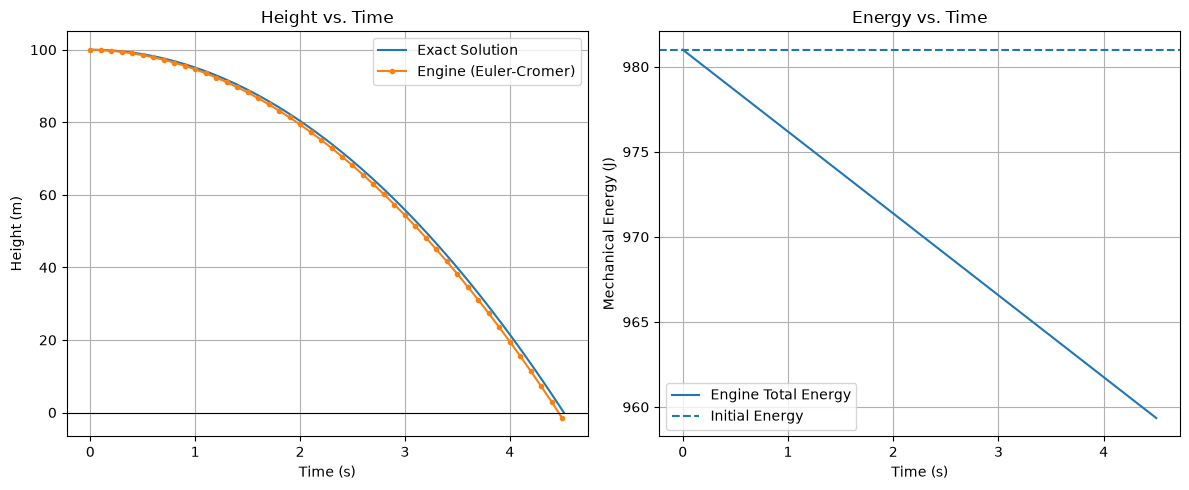

LAB 1 — Projectile
Engine impact time: 4.50 s
Exact impact time:  4.52 s

Engine impact velocity: -44.15 m/s
Exact impact velocity:  -44.29 m/s

Time percent error: 0.34%

Initial mechanical energy: 981.00 J
Energy at recorded impact:  959.35 J


In [2]:
# Parameters
h = 100.0
dt = 0.1
g = 9.81
m = 1.0

# Initialize the engine
fall_world = World(EulerCromer())

fall_body = Body(
    mass=m,
    pos=[0.0, h],
    vel=[0.0, 0.0],
    radius=0.1
)

fall_world.add_body(fall_body)
fall_world.add_force(Gravity(g))

# Run simulation using the engine
history = fall_world.run(duration=5.0, dt=dt)

# Extract recorded data
t = np.asarray(history["time"])
positions = np.asarray(history["positions"])
velocities = np.asarray(history["velocities"])
energy = np.asarray(history["total_energy"])

y = positions[:, 0, 1]
vy = velocities[:, 0, 1]

# Find the first recorded time the ball reaches or passes the ground
hit_index = np.flatnonzero(y <= 0)[0]

# Exact solution
t_exact_hit = np.sqrt(2 * h / g)
vy_exact = -g * t_exact_hit

t_exact = np.linspace(0, t_exact_hit, 500)
y_exact = h - 0.5 * g * t_exact**2

# Plot results
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

# Height vs. time
axes[0].plot(t_exact, y_exact, label="Exact Solution")
axes[0].plot(
    t[:hit_index + 1],
    y[:hit_index + 1],
    "o-",
    markersize=3,
    label="Engine (Euler-Cromer)"
)

axes[0].axhline(0, color="black", linewidth=0.8)
axes[0].set_xlabel("Time (s)")
axes[0].set_ylabel("Height (m)")
axes[0].set_title("Height vs. Time")
axes[0].legend()
axes[0].grid()

# Mechanical energy
axes[1].plot(
    t[:hit_index + 1],
    energy[:hit_index + 1],
    label="Engine Total Energy"
)
axes[1].axhline(
    energy[0],
    linestyle="--",
    label="Initial Energy"
)

axes[1].set_xlabel("Time (s)")
axes[1].set_ylabel("Mechanical Energy (J)")
axes[1].set_title("Energy vs. Time")
axes[1].legend()
axes[1].grid()

plt.tight_layout()
plt.show()

# Compare numerical and exact results
t_engine = t[hit_index]
vy_engine = vy[hit_index]

print("LAB 1 — Projectile")
print(f"Engine impact time: {t_engine:.2f} s")
print(f"Exact impact time:  {t_exact_hit:.2f} s")

print(f"\nEngine impact velocity: {vy_engine:.2f} m/s")
print(f"Exact impact velocity:  {vy_exact:.2f} m/s")

print(
    "\nTime percent error:",
    f"{abs(t_engine - t_exact_hit) / t_exact_hit * 100:.2f}%"
)

print(f"\nInitial mechanical energy: {energy[0]:.2f} J")
print(f"Energy at recorded impact:  {energy[hit_index]:.2f} J")

Lab 3 - Oscillations

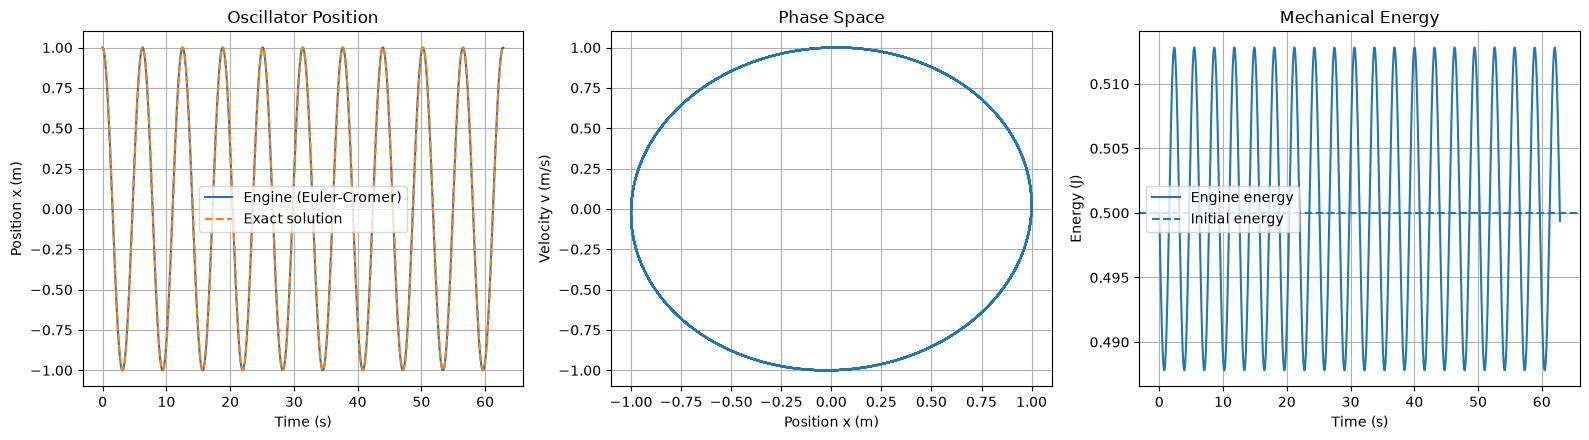

LAB 3 — Oscillator
Analytical period: 6.2832 s
Simulated duration: 62.85 s
Initial energy: 0.5000 J
Final energy: 0.4994 J
Minimum energy: 0.4878 J
Maximum energy: 0.5128 J
Energy range: 0.0250 J


In [3]:
# Parameters
x0 = 1.0
v0 = 0.0
k = 1.0
m = 1.0
dt = 0.05

omega = np.sqrt(k / m)
T = 2 * np.pi / omega

# Simulation duration: 10 periods
n_steps = int(round(10 * T / dt))
duration = n_steps * dt

# Initialize the engine
osc_world = World(EulerCromer())

osc_body = Body(
    mass=m,
    pos=[x0, 0.0],
    vel=[v0, 0.0],
    radius=0.05
)

osc_world.add_body(osc_body)
osc_world.add_force(
    Spring(osc_body, k, anchor=(0.0, 0.0))
)

# Run simulation using engine calls
history = osc_world.run(duration=duration, dt=dt)

# Extract recorded data
t = np.asarray(history["time"])
positions = np.asarray(history["positions"])
velocities = np.asarray(history["velocities"])
energy = np.asarray(history["total_energy"])

x = positions[:, 0, 0]
v = velocities[:, 0, 0]

# Exact solution for comparison
t_exact = np.linspace(0, duration, 1000)
x_exact = x0 * np.cos(omega * t_exact)

E_exact = 0.5 * k * x0**2 + 0.5 * m * v0**2

# Plot results
fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))

# Position vs. time
axes[0].plot(t, x, label="Engine (Euler-Cromer)")
axes[0].plot(t_exact, x_exact, "--", label="Exact solution")
axes[0].set_xlabel("Time (s)")
axes[0].set_ylabel("Position x (m)")
axes[0].set_title("Oscillator Position")
axes[0].legend()
axes[0].grid()

# Phase-space plot
axes[1].plot(x, v)
axes[1].set_xlabel("Position x (m)")
axes[1].set_ylabel("Velocity v (m/s)")
axes[1].set_title("Phase Space")
axes[1].grid()

# Total mechanical energy
axes[2].plot(t, energy, label="Engine energy")
axes[2].axhline(
    E_exact, linestyle="--", label="Initial energy"
)
axes[2].set_xlabel("Time (s)")
axes[2].set_ylabel("Energy (J)")
axes[2].set_title("Mechanical Energy")
axes[2].legend()
axes[2].grid()

plt.tight_layout()
plt.show()

# Validation
print("LAB 3 — Oscillator")
print(f"Analytical period: {T:.4f} s")
print(f"Simulated duration: {duration:.2f} s")
print(f"Initial energy: {energy[0]:.4f} J")
print(f"Final energy: {energy[-1]:.4f} J")
print(f"Minimum energy: {np.min(energy):.4f} J")
print(f"Maximum energy: {np.max(energy):.4f} J")
print(f"Energy range: {np.ptp(energy):.4f} J")

Lab 4 - Collisions

In [4]:
# Parameters
m1 = 2.0
m2 = 3.0
u1 = 4.0
u2 = 0.0
dt_collision = 0.01
radius = 0.1

# Perfectly elastic collision, e = 1
world_e1 = World(EulerCromer(), restitution=1.0)

a_e1 = Body(m1, [-0.11, 0.0], [u1, 0.0], radius=radius)
b_e1 = Body(m2, [ 0.11, 0.0], [u2, 0.0], radius=radius)

world_e1.add_body(a_e1)
world_e1.add_body(b_e1)

hist_e1 = world_e1.run(
    duration=dt_collision,
    dt=dt_collision
)

# Partially inelastic collision, e = 0.5
world_e05 = World(EulerCromer(), restitution=0.5)

a_e05 = Body(m1, [-0.11, 0.0], [u1, 0.0], radius=radius)
b_e05 = Body(m2, [ 0.11, 0.0], [u2, 0.0], radius=radius)

world_e05.add_body(a_e05)
world_e05.add_body(b_e05)

hist_e05 = world_e05.run(
    duration=dt_collision,
    dt=dt_collision
)

# Perfectly inelastic collision, e = 0
world_e0 = World(EulerCromer(), restitution=0.0)

a_e0 = Body(m1, [-0.11, 0.0], [u1, 0.0], radius=radius)
b_e0 = Body(m2, [ 0.11, 0.0], [u2, 0.0], radius=radius)

world_e0.add_body(a_e0)
world_e0.add_body(b_e0)

hist_e0 = world_e0.run(
    duration=dt_collision,
    dt=dt_collision
)

# Final velocities calculated by the engine
engine_velocities = np.array([
    [a_e1.v[0], b_e1.v[0]],
    [a_e05.v[0], b_e05.v[0]],
    [a_e0.v[0], b_e0.v[0]]
])

# Analytical results from the original 1-D collision problem
expected_velocities = np.array([
    [-0.8, 3.2],
    [ 0.4, 2.4],
    [ 1.6, 1.6]
])

# Recorded momentum and kinetic energy
histories = [hist_e1, hist_e05, hist_e0]

p_before = np.array([
    history["momentum"][0][0]
    for history in histories
])

p_after = np.array([
    history["momentum"][-1][0]
    for history in histories
])

ke_before = np.array([
    history["kinetic_energy"][0]
    for history in histories
])

ke_after = np.array([
    history["kinetic_energy"][-1]
    for history in histories
])

# Display the comparison
collision_results = np.column_stack((
    np.array([1.0, 0.5, 0.0]),
    engine_velocities,
    expected_velocities,
    p_before,
    p_after,
    ke_before,
    ke_after
))

print("LAB 4 — Collisions")
print(
    "Columns: e, v1_engine, v2_engine, "
    "v1_expected, v2_expected, p_before, "
    "p_after, KE_before, KE_after"
)
print(collision_results)

# Validation checks
assert np.allclose(engine_velocities, expected_velocities)
assert np.allclose(p_before, p_after)
assert np.isclose(ke_before[0], ke_after[0])
assert ke_after[0] > ke_after[1] > ke_after[2]

print("\nAll collision checks passed.")
print("Momentum is conserved in all three cases.")
print("Kinetic energy is conserved for e = 1.")
print("Kinetic energy decreases as restitution decreases.")

LAB 4 — Collisions
Columns: e, v1_engine, v2_engine, v1_expected, v2_expected, p_before, p_after, KE_before, KE_after
[[ 1.  -0.8  3.2 -0.8  3.2  8.   8.  16.  16. ]
 [ 0.5  0.4  2.4  0.4  2.4  8.   8.  16.   8.8]
 [ 0.   1.6  1.6  1.6  1.6  8.   8.  16.   6.4]]

All collision checks passed.
Momentum is conserved in all three cases.
Kinetic energy is conserved for e = 1.
Kinetic energy decreases as restitution decreases.


Part C - An Original Multi-Body Scene
Description: Simulates a system with 3 balls under the influence of gravity and drag forces with collisions. Checks conservation of energy and momentum and provides trajectort plots and energy analysis.


Simulation Results

Initial kinetic energy: 7.440 J
Initial potential energy: 171.086 J
Initial total energy: 178.526 J

Final kinetic energy: 8.501 J
Final potential energy: 16.164 J
Final total energy: 24.665 J

Total energy decrease: 153.861 J
Percentage energy decrease: 86.18%


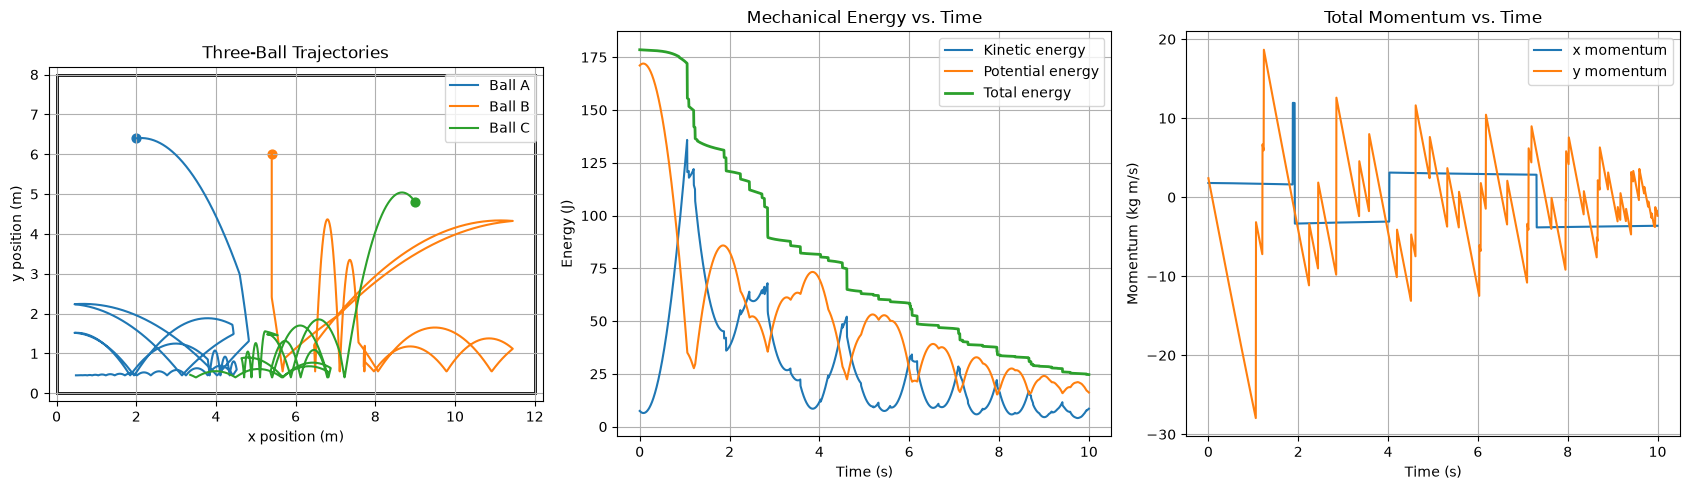


Collision Checks

Ball A and Ball B: minimum separation = 1.000 m, contact distance = 1.000 m
Ball A and Ball C: minimum separation = 0.850 m, contact distance = 0.850 m
Ball B and Ball C: minimum separation = 0.950 m, contact distance = 0.950 m
All three pairs reached contact.
The collision checks passed.

Energy Check

Initial energy: 178.526 J
Final energy: 24.665 J
Energy decreased overall: True
Energy decreases because drag dissipates energy and partially inelastic collisions reduce kinetic energy.

Elastic collision test

Initial momentum: [0. 0.]
Final momentum:   [0. 0.]
Initial kinetic energy: 1.000000 J
Final kinetic energy:   1.000000 J
Momentum conserved: True
Kinetic energy conserved: True


In [5]:
# Box boundaries: xmin, xmax, ymin, ymax
bounds = (0.0, 12.0, 0.0, 8.0)

world = World(
    EulerCromer(),
    bounds=bounds,
    restitution=0.88
)

# Create three balls with different masses, positions, and velocities
ball_a = Body(
    1.0, [2.0, 6.4], [3.0, 0.4],
    radius=0.45, name="Ball A"
)

ball_b = Body(
    1.2, [5.4, 6.0], [0.0, 0.2],
    radius=0.55, name="Ball B"
)

ball_c = Body(
    0.8, [9.0, 4.8], [-1.5, 2.2],
    radius=0.40, name="Ball C"
)

world.add_body(ball_a)
world.add_body(ball_b)
world.add_body(ball_c)

# Add forces
world.add_force(Gravity(g=9.81))
world.add_force(Drag(c=0.008))

duration = 10.0
dt = 0.005

history = world.run(duration=duration, dt=dt)

# Recorded quantities
t = np.asarray(history["time"])
positions = np.asarray(history["positions"])
velocities = np.asarray(history["velocities"])

kinetic = np.asarray(history["kinetic_energy"])
potential = np.asarray(history["potential_energy"])
total_energy = np.asarray(history["total_energy"])
momentum = np.asarray(history["momentum"])

print("\nSimulation Results")

print(f"\nInitial kinetic energy: {kinetic[0]:.3f} J")
print(f"Initial potential energy: {potential[0]:.3f} J")
print(f"Initial total energy: {total_energy[0]:.3f} J")

print(f"\nFinal kinetic energy: {kinetic[-1]:.3f} J")
print(f"Final potential energy: {potential[-1]:.3f} J")
print(f"Final total energy: {total_energy[-1]:.3f} J")

energy_loss = total_energy[0] - total_energy[-1]

print(f"\nTotal energy decrease: {energy_loss:.3f} J")
print(
    f"Percentage energy decrease: "
    f"{100 * energy_loss / total_energy[0]:.2f}%"
)


# Plots
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

xmin, xmax, ymin, ymax = bounds

# Trajectories inside the box
ax = axes[0]

ax.add_patch(
    Rectangle(
        (xmin, ymin),
        xmax - xmin,
        ymax - ymin,
        fill=False,
        linewidth=2,
        edgecolor="black"
    )
)

for i, body in enumerate(world.bodies):
    ax.plot(
        positions[:, i, 0],
        positions[:, i, 1],
        label=body.name
    )

    ax.scatter(
        positions[0, i, 0],
        positions[0, i, 1],
        marker="o",
        s=40
    )

ax.set_xlim(xmin - 0.2, xmax + 0.2)
ax.set_ylim(ymin - 0.2, ymax + 0.2)
ax.set_aspect("equal", adjustable="box")
ax.set_xlabel("x position (m)")
ax.set_ylabel("y position (m)")
ax.set_title("Three-Ball Trajectories")
ax.legend()
ax.grid()


# Mechanical energy
ax = axes[1]

ax.plot(t, kinetic, label="Kinetic energy")
ax.plot(t, potential, label="Potential energy")
ax.plot(t, total_energy, label="Total energy", linewidth=2)

ax.set_xlabel("Time (s)")
ax.set_ylabel("Energy (J)")
ax.set_title("Mechanical Energy vs. Time")
ax.legend()
ax.grid()


# Total momentum
ax = axes[2]

ax.plot(t, momentum[:, 0], label="x momentum")
ax.plot(t, momentum[:, 1], label="y momentum")

ax.set_xlabel("Time (s)")
ax.set_ylabel("Momentum (kg m/s)")
ax.set_title("Total Momentum vs. Time")
ax.legend()
ax.grid()

plt.tight_layout()
plt.show()

# Validate Conservation Laws
print("\nCollision Checks\n")

assert len(world.bodies) == 3
assert len(world.forces) >= 2

for i in range(len(world.bodies)):
    for j in range(i + 1, len(world.bodies)):

        separation = np.linalg.norm(
            positions[:, j, :] - positions[:, i, :],
            axis=1
        )

        contact_distance = (
            world.bodies[i].radius
            + world.bodies[j].radius
        )

        minimum_separation = np.min(separation)

        print(
            f"{world.bodies[i].name} and "
            f"{world.bodies[j].name}: "
            f"minimum separation = {minimum_separation:.3f} m, "
            f"contact distance = {contact_distance:.3f} m"
        )

        # Verify that this pair reached contact
        assert np.isclose(
            minimum_separation,
            contact_distance,
            atol=1e-6
        )

print("All three pairs reached contact.")
print("The collision checks passed.")

print("\nEnergy Check\n")
print(f"Initial energy: {total_energy[0]:.3f} J")
print(f"Final energy: {total_energy[-1]:.3f} J")
print(f"Energy decreased overall: {total_energy[-1] < total_energy[0]}")

print("Energy decreases because drag dissipates energy and partially inelastic collisions reduce kinetic energy.")


# Separate world with two equal-mass balls, no forces, no walls
elastic_world = World(
    EulerCromer(),
    restitution=1.0
)

elastic_world.add_body(
    Body(1.0, [-1.0, 0.0], [1.0, 0.0],
         radius=0.5, name="Left")
)

elastic_world.add_body(
    Body(1.0, [1.0, 0.0], [-1.0, 0.0],
         radius=0.5, name="Right")
)

elastic_history = elastic_world.run(
    duration=0.6,
    dt=0.005
)

p_initial = np.asarray(elastic_history["momentum"][0])
p_final = np.asarray(elastic_history["momentum"][-1])

ke_initial = elastic_history["kinetic_energy"][0]
ke_final = elastic_history["kinetic_energy"][-1]

print("\nElastic collision test\n")
print("Initial momentum:", p_initial)
print("Final momentum:  ", p_final)
print(f"Initial kinetic energy: {ke_initial:.6f} J")
print(f"Final kinetic energy:   {ke_final:.6f} J")

assert np.allclose(p_initial, p_final, atol=1e-10)
assert np.isclose(ke_initial, ke_final, atol=1e-10)

print("Momentum conserved:", np.allclose(p_initial, p_final))
print("Kinetic energy conserved:", np.isclose(ke_initial, ke_final))

Simulation Description: This simulation tests my engine using a system of 3 balls under the influence of gravitational and drag forces, starting at some initial displacement, mass, velocity, and radius. This simulation uses the Euler-Cromer integrator to keep energy error bounded. Uses the world class to track momentum, energy, and collision history. The simulation correct predicts the loss of total enegry over time due to both drag forces and non-elastic collisons while momentum is also not conserved due to external forces like gravity. Using a seperate world, I show that momentum is conserved for this engine in the case of a system with elastic collisions.